In [1]:
from pathlib import Path

import numpy as np
import pandas as pd

import torch
from torch import nn

from aif import DataModule, Module, Trainer

In [2]:
class KaggleHousePricesDataset(DataModule):
    def __init__(self, root='../data', batch_size=64, train=None, val=None):
        super().__init__(batch_size=batch_size)

        if train is None:
            train_path = f'{root}/house_prices_kaggle/train.csv'
            val_path = f'{root}/house_prices_kaggle/test.csv'

            self.raw_train = pd.read_csv(train_path)
            self.raw_val = pd.read_csv(val_path)

            self.train = None
            self.val = None
        else:
            self.train = train
            self.val = val

    def preprocess(self):
        label = 'SalePrice'
        features = pd.concat((
            self.raw_train.drop(columns=['Id', label]),
            self.raw_val.drop(columns=['Id'])
        ))

        numeric_features = features.select_dtypes('number').columns
        features[numeric_features] = features[numeric_features].apply(
            lambda x: (x - x.mean()) / (x.std())
        )
        features[numeric_features] = features[numeric_features].fillna(0)

        features = pd.get_dummies(features, dummy_na=True)

        self.train = features[:self.raw_train.shape[0]].copy()
        self.train[label] = self.raw_train[label]
        self.val = features[self.raw_train.shape[0]:].copy()

    def get_dataloader(self, train):
        label = 'SalePrice'
        data = self.train if train else self.val

        if label not in data:
            return

        get_tensor = lambda x: torch.tensor(
            x.values.astype(float),
            dtype=torch.float32
        )

        tensors = (
            get_tensor(data.drop(columns=[label])),
            torch.log(get_tensor(data[label])).reshape((-1, 1))
        )

        return self._get_tensorloader(tensors, train)

In [3]:
data = KaggleHousePricesDataset()

data.raw_train.shape, data.raw_val.shape

((1460, 81), (1459, 80))

In [4]:
data.preprocess()

data.train.shape, data.val.shape

((1460, 331), (1459, 330))

In [5]:
class LinearRegression(Module):
    def __init__(self, num_inputs, lr, sigma=0.01):
        super().__init__(lr)

        self.net = nn.Linear(num_inputs, 1)

        self.net.weight.data.normal_(0, sigma)
        self.net.bias.data.fill_(0)

    def forward(self, X):
        return self.net(X)

    def loss(self, y_hat, y):
        return nn.MSELoss()(y_hat, y)

    def get_w_b(self):
        return self.net.weight.detach(), self.net.bias.detach()

In [6]:
num_inputs = data.train.shape[1] - 1  # all columns except SalePrice

model = LinearRegression(num_inputs, 0.01)

log_prices = np.log(data.train.iloc[:, -1].to_numpy())
model.net.bias.data.fill_(log_prices.mean())

tensor([12.0241])

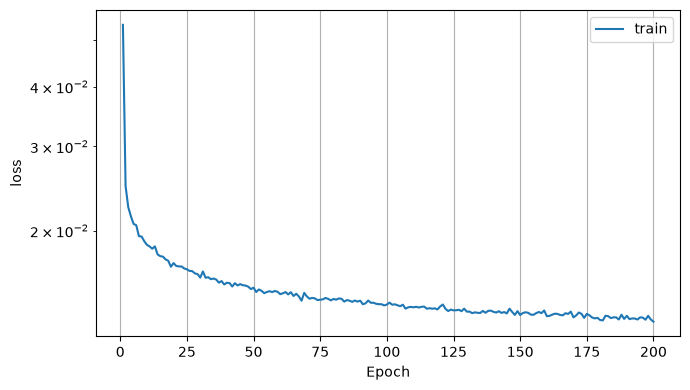

Epoch 200/200 | train_loss: 0.012909


In [7]:
trainer = Trainer(max_epochs=200, yscale='log')

trainer.fit(model, data)

In [8]:
with torch.no_grad():
    preds = torch.exp(model(torch.tensor(data.val.values.astype(float), dtype=torch.float32))).squeeze(1)

In [9]:
submission_df = pd.DataFrame({
    'Id': data.raw_val.Id,
    'SalePrice': preds.detach().numpy()
})

display(submission_df)

,Id,SalePrice
0,1461,112704.273438
1,1462,148707.078125
2,1463,167772.000000
3,1464,190834.453125
4,1465,195121.437500
...,...,...
1454,2915,84971.804688
1455,2916,84015.976562
1456,2917,155063.734375
1457,2918,109510.007812


In [11]:
submissions = Path('../submissions')
submissions.mkdir(exist_ok=True)
submission_df.to_csv(submissions / 'submission_log_space_200_epochs_mean_bias.csv', index=False)